# Scale_Error_DC — Visual EDA & Annotation Audit

Notebook này được tổ chức theo một flow duy nhất:

**Load dataset → tạo index → overview → raw-vs-annotation → class appearance → scale/hard cases → sanity check → montage cuối.**

Mục tiêu là nhìn nhanh dataset object detection trước khi train, không biến notebook thành một báo cáo thống kê dài dòng.

## 1. Setup & visual style

Một cell duy nhất cho import, seed và style để toàn notebook nhất quán.

In [1]:
from __future__ import annotations

import os
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
from PIL import Image, ImageDraw, ImageFont

SEED = 42
rng = np.random.default_rng(SEED)

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
EXPECTED_CLASSES = ["DiVat", "DiVatLoiLom", "LoiChi", "LoiNhua", "LoiTray"]

plt.rcParams.update({
    "figure.figsize": (12, 7),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "font.size": 10,
})

pd.set_option("display.max_colwidth", 80)


## 2. Locate dataset & read `data.yaml`

Nếu notebook không tự tìm thấy dataset, set biến môi trường:

```python
os.environ["SCALE_ERROR_DATASET"] = "/path/to/dataset"
```

In [2]:
def find_dataset_root() -> Path:
    candidates = []

    env_path = os.getenv("SCALE_ERROR_DATASET")
    if env_path:
        candidates.append(Path(env_path))

    candidates += [
        Path("data/raw/scale_error_dc_v26"),
        Path("data/raw/scale-error-dc"),
        Path("data/raw/scale_error_dc_v26"),
        Path("data/raw/scale_error_dc"),
        Path("../data/raw/scale_error_dc_v26"),
        Path("../data/raw/scale_error_dc"),
    ]

    for candidate in candidates:
        if (candidate / "data.yaml").exists():
            return candidate.resolve()

    data_input = Path("data/raw")
    if data_input.exists():
        for yaml_path in data_input.rglob("data.yaml"):
            if (yaml_path.parent / "train" / "images").exists():
                return yaml_path.parent.resolve()

    raise FileNotFoundError(
        "Không tìm thấy dataset. Set SCALE_ERROR_DATASET tới folder chứa data.yaml."
    )


def normalize_names(names) -> dict[int, str]:
    if isinstance(names, list):
        return {i: str(name) for i, name in enumerate(names)}
    if isinstance(names, dict):
        return {int(k): str(v) for k, v in names.items()}
    raise TypeError("`names` trong data.yaml phải là list hoặc dict.")


DATASET_ROOT = find_dataset_root()

with (DATASET_ROOT / "data.yaml").open("r", encoding="utf-8") as f:
    DATA_YAML = yaml.safe_load(f)

CLASS_NAMES = normalize_names(DATA_YAML["names"])
NC = len(CLASS_NAMES)

print(f"Dataset : {DATASET_ROOT}")
print(f"Classes : {NC}")
for class_id, class_name in CLASS_NAMES.items():
    print(f"  {class_id}: {class_name}")

if list(CLASS_NAMES.values()) != EXPECTED_CLASSES:
    print("\n⚠ Class list khác EXPECTED_CLASSES — kiểm tra lại data.yaml nếu không chủ ý.")


Dataset : D:\HOCsauvaufngdung\scale-error-yolo26\data\raw\scale_error_dc
Classes : 5
  0: DiVat
  1: DiVatLoiLom
  2: LoiChi
  3: LoiNhua
  4: LoiTray


## 3. Dataset utilities

Các hàm đọc split, ảnh và YOLO label nằm cùng một chỗ. Từ đây trở đi notebook không lặp lại logic đọc file.

In [3]:
def split_dir(split: str) -> Path | None:
    aliases = {
        "train": ["train"],
        "val": ["valid", "val"],
        "test": ["test"],
    }
    for folder in aliases[split]:
        path = DATASET_ROOT / folder
        if (path / "images").exists():
            return path
    return None


def list_images(folder: Path) -> list[Path]:
    if not folder.exists():
        return []
    return sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    )


def label_path_for_image(image_path: Path, split_path: Path) -> Path:
    rel = image_path.relative_to(split_path / "images")
    return (split_path / "labels" / rel).with_suffix(".txt")


def parse_yolo_label(label_path: Path):
    boxes = []
    issues = []

    if not label_path.exists():
        return boxes, issues

    for line_no, raw in enumerate(label_path.read_text(encoding="utf-8").splitlines(), start=1):
        raw = raw.strip()
        if not raw:
            continue

        parts = raw.split()
        if len(parts) != 5:
            issues.append((line_no, "wrong_column_count", raw))
            continue

        try:
            cls_f, x, y, w, h = map(float, parts)
        except ValueError:
            issues.append((line_no, "non_numeric_value", raw))
            continue

        cls = int(cls_f)
        if cls_f != cls:
            issues.append((line_no, "class_id_not_integer", raw))
            continue

        if cls not in CLASS_NAMES:
            issues.append((line_no, "class_id_out_of_range", raw))
            continue

        if w <= 0 or h <= 0:
            issues.append((line_no, "non_positive_box", raw))
            continue

        boxes.append((cls, x, y, w, h))

    return boxes, issues


SPLITS = {name: split_dir(name) for name in ["train", "val", "test"]}
SPLITS = {name: path for name, path in SPLITS.items() if path is not None}
SPLITS


{'train': WindowsPath('D:/HOCsauvaufngdung/scale-error-yolo26/data/raw/scale_error_dc/train'),
 'val': WindowsPath('D:/HOCsauvaufngdung/scale-error-yolo26/data/raw/scale_error_dc/valid')}

## 4. Build one reusable dataset index

Quét dataset **một lần** để tạo:

- `image_df`: một dòng / ảnh;
- `object_df`: một dòng / bounding box;
- `issue_df`: annotation lỗi cú pháp hoặc class ID.

Các cell EDA phía sau chỉ lọc các bảng này nên gọn và nhanh hơn.

In [4]:
image_rows = []
object_rows = []
issue_rows = []

for split, split_path in SPLITS.items():
    for image_path in list_images(split_path / "images"):
        label_path = label_path_for_image(image_path, split_path)
        boxes, issues = parse_yolo_label(label_path)

        with Image.open(image_path) as im:
            width, height = im.size

        image_rows.append({
            "split": split,
            "image_path": image_path,
            "label_path": label_path,
            "label_exists": label_path.exists(),
            "width": width,
            "height": height,
            "n_objects": len(boxes),
        })

        for line_no, issue_type, raw in issues:
            issue_rows.append({
                "split": split,
                "image": image_path.name,
                "label": label_path.name,
                "line": line_no,
                "issue": issue_type,
                "raw": raw,
            })

        for obj_idx, (cls, x, y, w, h) in enumerate(boxes):
            x1, y1 = x - w / 2, y - h / 2
            x2, y2 = x + w / 2, y + h / 2

            object_rows.append({
                "split": split,
                "image_path": image_path,
                "label_path": label_path,
                "object_id": obj_idx,
                "class_id": cls,
                "class_name": CLASS_NAMES[cls],
                "x": x,
                "y": y,
                "w": w,
                "h": h,
                "area": w * h,
                "aspect": w / h,
                "edge_distance": min(x1, y1, 1 - x2, 1 - y2),
            })

image_df = pd.DataFrame(image_rows)
object_df = pd.DataFrame(object_rows)
issue_df = pd.DataFrame(issue_rows)

train_images = image_df.loc[image_df["split"] == "train", "image_path"].tolist()

print(f"Images : {len(image_df):,}")
print(f"Objects: {len(object_df):,}")
print(f"Parse issues: {len(issue_df):,}")


Images : 7,346
Objects: 12,294
Parse issues: 0


## 5. Compact overview

Chỉ giữ các thống kê thật sự hữu ích trước khi nhìn ảnh: số ảnh theo split và số object theo class.

,images,objects
split,,
train,5578,9166
val,1768,3128


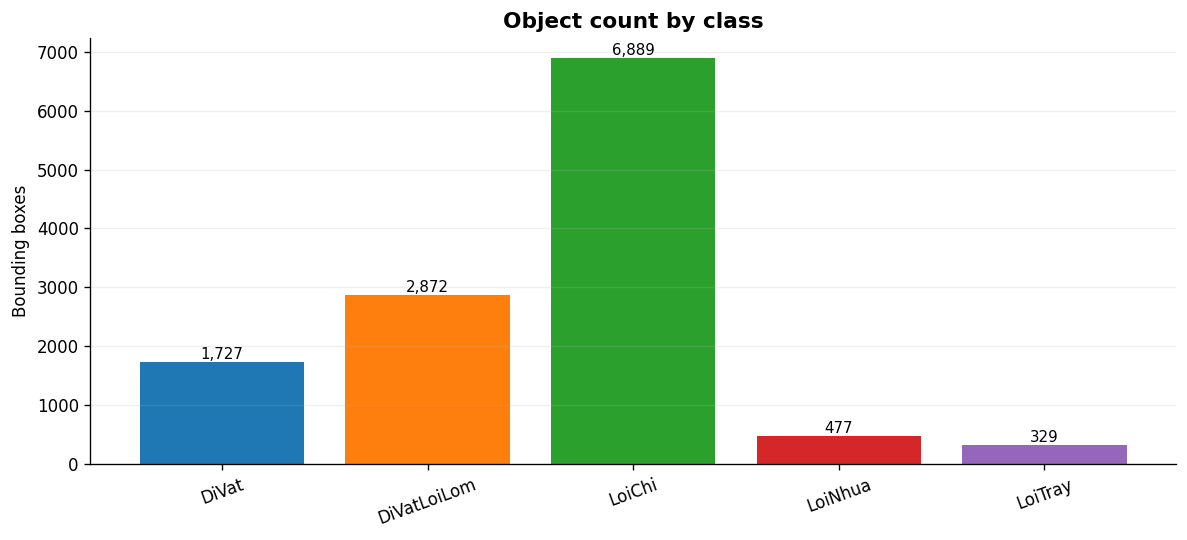

In [5]:
split_order = [s for s in ["train", "val", "test"] if s in image_df["split"].unique()]
split_summary = (
    image_df.groupby("split")
    .agg(images=("image_path", "size"), objects=("n_objects", "sum"))
    .reindex(split_order)
)

display(split_summary)

class_counts = (
    object_df["class_name"]
    .value_counts()
    .reindex(CLASS_NAMES.values(), fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4.6))
overview_colors = [plt.get_cmap("tab10")(i % 10) for i in range(len(class_counts))]
bars = ax.bar(class_counts.index, class_counts.values, color=overview_colors)
ax.set_title("Object count by class")
ax.set_ylabel("Bounding boxes")
ax.grid(axis="y", alpha=0.2)
ax.tick_params(axis="x", rotation=20)

for bar, value in zip(bars, class_counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:,}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

plt.tight_layout()
plt.show()


## 6. Visualization helpers

Mỗi class có một màu cố định. Label được vẽ có nền, gallery có spacing gọn và title ngắn để không che ảnh.

In [6]:
def build_class_colors(class_names: dict[int, str]) -> dict[int, tuple[int, int, int]]:
    cmap = plt.get_cmap("tab10")
    colors = {}
    for i, class_id in enumerate(class_names):
        rgb = mcolors.to_rgb(cmap(i % 10))
        colors[class_id] = tuple(int(v * 255) for v in rgb)
    return colors


CLASS_COLORS = build_class_colors(CLASS_NAMES)


def xywhn_to_xyxy(box, image_width: int, image_height: int):
    cls, x, y, w, h = box
    x1 = (x - w / 2) * image_width
    y1 = (y - h / 2) * image_height
    x2 = (x + w / 2) * image_width
    y2 = (y + h / 2) * image_height
    return cls, x1, y1, x2, y2


def _font_for_image(width: int, height: int):
    size = max(12, round(min(width, height) / 45))
    try:
        return ImageFont.truetype("DejaVuSans.ttf", size=size)
    except OSError:
        return ImageFont.load_default()


def draw_boxes(image_path: Path, label_path: Path, show_labels: bool = True) -> Image.Image:
    image = Image.open(image_path).convert("RGB")
    width, height = image.size
    draw = ImageDraw.Draw(image)
    font = _font_for_image(width, height)
    line_width = max(2, round(min(width, height) / 220))

    boxes, _ = parse_yolo_label(label_path)
    for box in boxes:
        cls, x1, y1, x2, y2 = xywhn_to_xyxy(box, width, height)
        color = CLASS_COLORS.get(cls, (255, 255, 255))

        draw.rectangle([x1, y1, x2, y2], outline=color, width=line_width)

        if show_labels:
            label = CLASS_NAMES.get(cls, str(cls))
            bbox = draw.textbbox((0, 0), label, font=font)
            tw, th = bbox[2] - bbox[0], bbox[3] - bbox[1]
            tx = max(0, int(x1))
            ty = max(0, int(y1) - th - 8)
            draw.rectangle([tx, ty, tx + tw + 10, ty + th + 6], fill=color)
            draw.text((tx + 5, ty + 2), label, fill="white", font=font)

    return image


def crop_box(image: Image.Image, box, padding_ratio: float = 0.20) -> Image.Image:
    width, height = image.size
    _, x1, y1, x2, y2 = xywhn_to_xyxy(box, width, height)

    bw, bh = x2 - x1, y2 - y1
    pad_x, pad_y = bw * padding_ratio, bh * padding_ratio

    x1 = max(0, int(x1 - pad_x))
    y1 = max(0, int(y1 - pad_y))
    x2 = min(width, int(x2 + pad_x))
    y2 = min(height, int(y2 + pad_y))

    return image.crop((x1, y1, x2, y2))


def short_name(path: Path, max_len: int = 28) -> str:
    name = path.stem
    return name if len(name) <= max_len else name[: max_len - 1] + "…"


def show_gallery(items, title: str, cols: int = 4, cell_size: float = 3.0):
    items = list(items)
    if not items:
        print("Không có ảnh phù hợp.")
        return

    cols = min(cols, len(items))
    rows = int(np.ceil(len(items) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * cell_size, rows * cell_size))
    axes = np.atleast_1d(axes).ravel()

    for ax in axes:
        ax.axis("off")

    for ax, item in zip(axes, items):
        ax.imshow(item["image"])
        ax.set_title(item.get("title", ""), fontsize=9, pad=5)
        ax.axis("off")

    fig.suptitle(title, fontsize=15, fontweight="bold", y=1.01)
    fig.tight_layout(pad=0.8)
    plt.show()


def sample_paths(paths, n: int):
    paths = list(paths)
    if not paths:
        return []
    idx = rng.choice(len(paths), size=min(n, len(paths)), replace=False)
    return [paths[int(i)] for i in np.atleast_1d(idx)]


# PHẦN A — VISUAL CHECK CƠ BẢN

## 7. Raw vs annotation — đặt cạnh nhau

Không tách raw và annotated thành hai cell xa nhau nữa. Mỗi hàng là **cùng một ảnh**, bên trái raw và bên phải annotation để nhìn lệch box/sai class nhanh hơn.

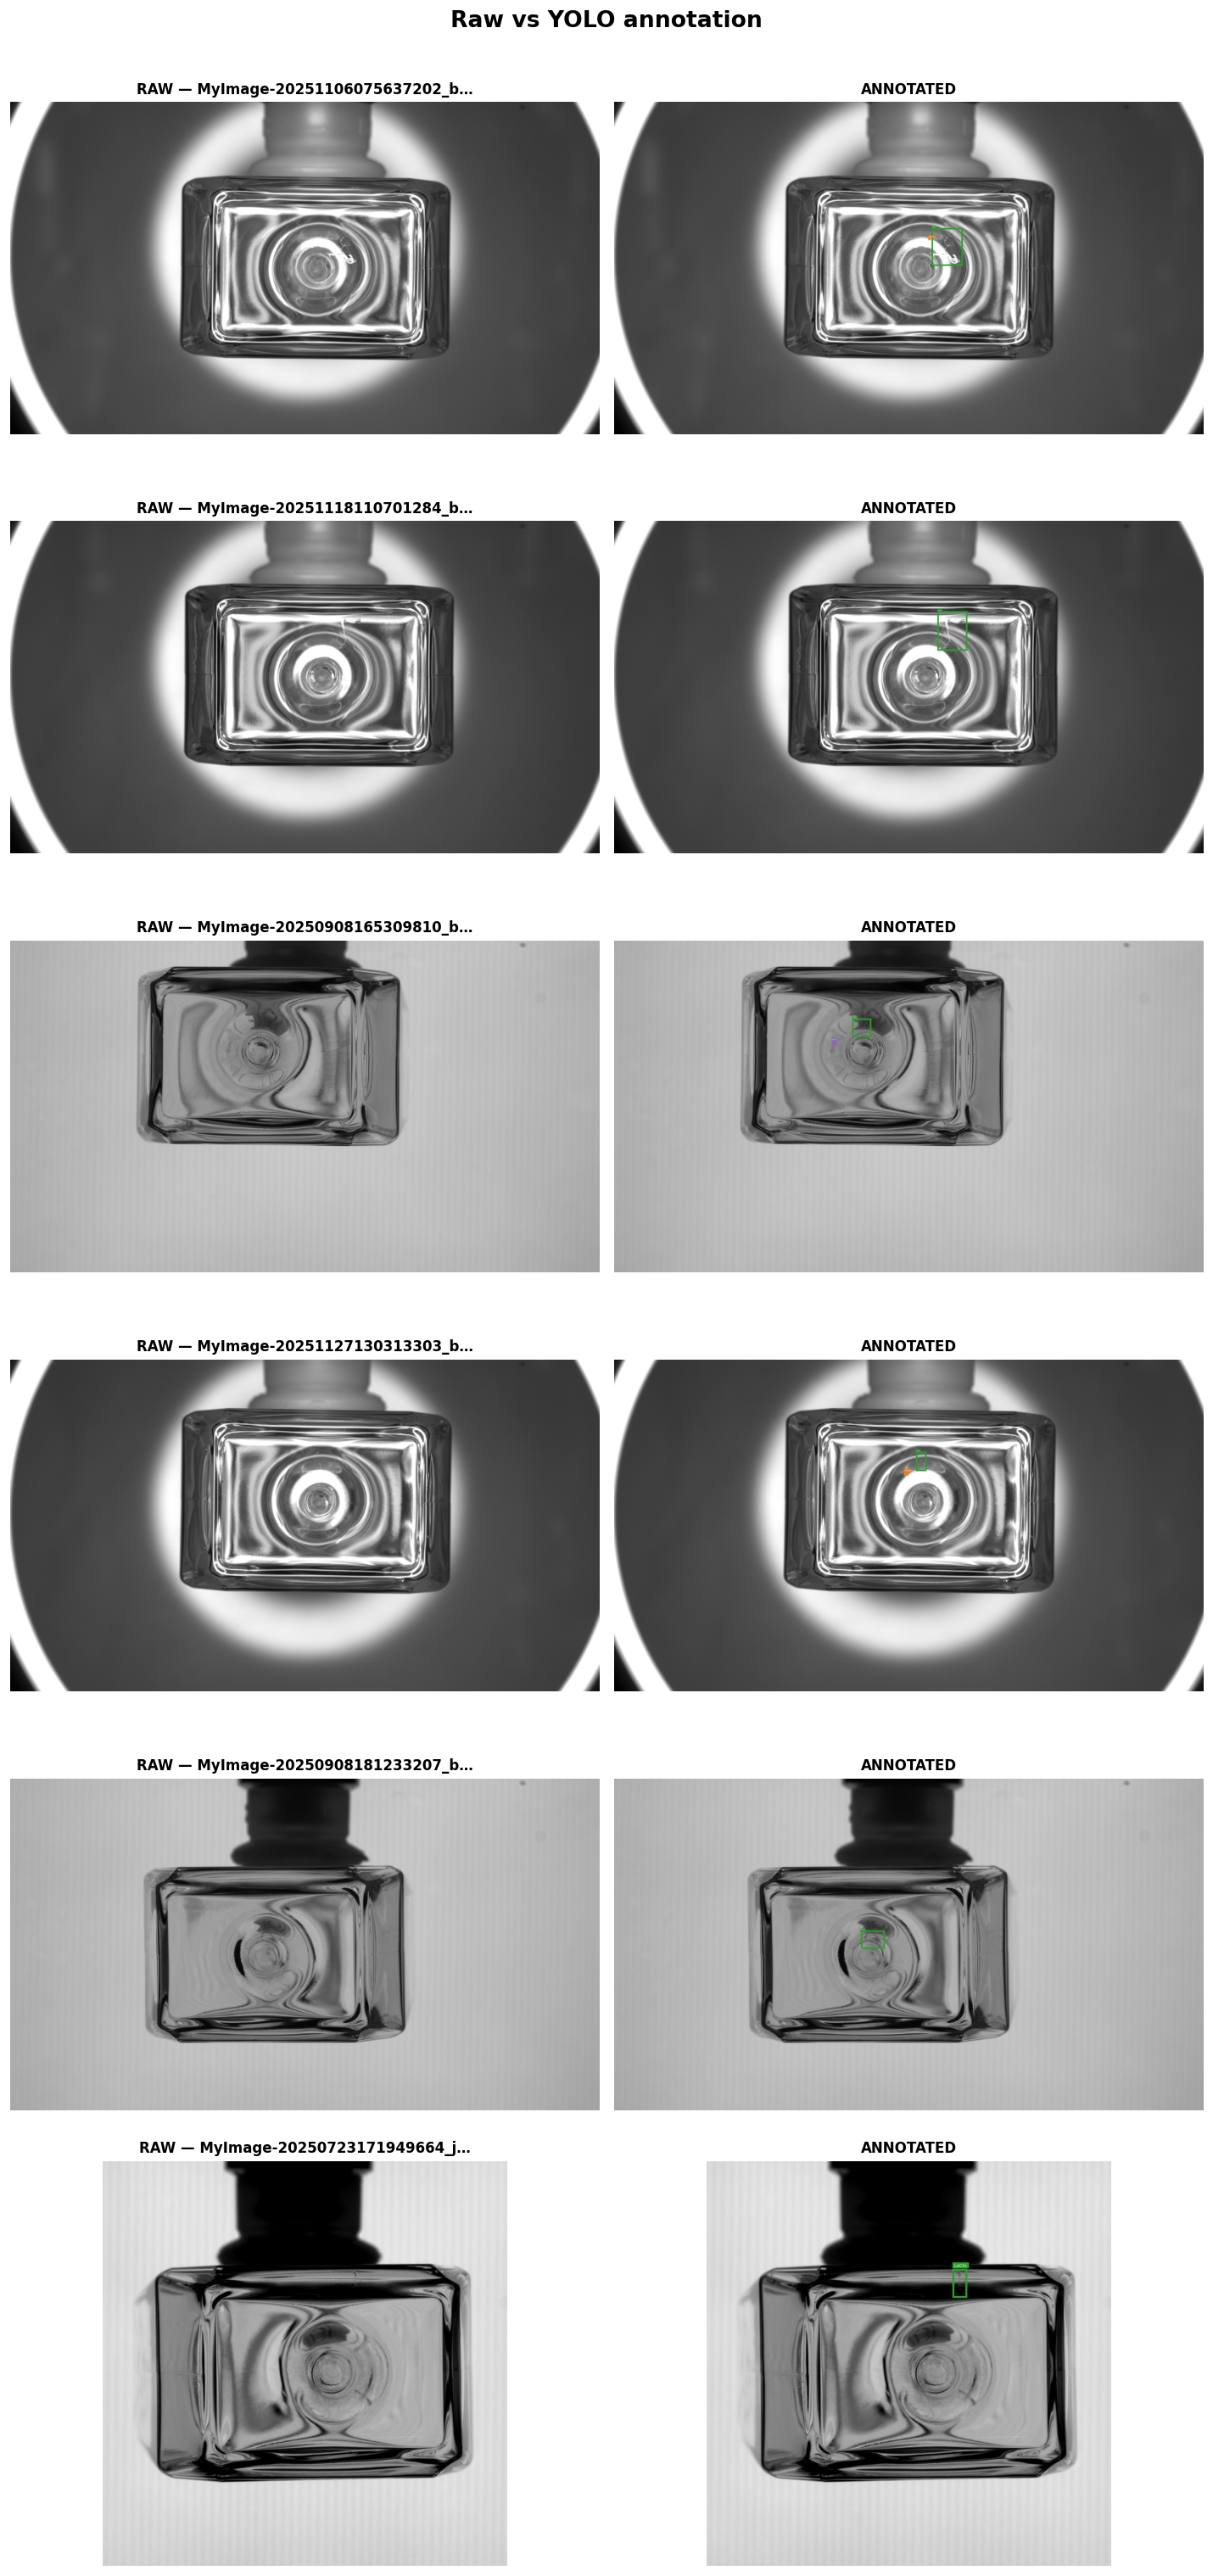

In [7]:
train_dir = SPLITS["train"]
selected = sample_paths(train_images, n=6)

fig, axes = plt.subplots(len(selected), 2, figsize=(12, 4.2 * len(selected)))
axes = np.atleast_2d(axes)

for row, image_path in enumerate(selected):
    label_path = label_path_for_image(image_path, train_dir)
    raw = Image.open(image_path).convert("RGB")
    annotated = draw_boxes(image_path, label_path)

    axes[row, 0].imshow(raw)
    axes[row, 0].set_title(f"RAW — {short_name(image_path)}", fontsize=10)
    axes[row, 1].imshow(annotated)
    axes[row, 1].set_title("ANNOTATED", fontsize=10)

    for col in range(2):
        axes[row, col].axis("off")

fig.suptitle("Raw vs YOLO annotation", fontsize=16, fontweight="bold", y=1.002)
fig.tight_layout(pad=1.0)
plt.show()


# PHẦN B — CLASS APPEARANCE

## 8. Defect crop theo từng class

Crop object là view quan trọng nhất với defect nhỏ. Mỗi class xem một grid riêng để nhận ra texture/shape thật thay vì bị scene nền lấn át.

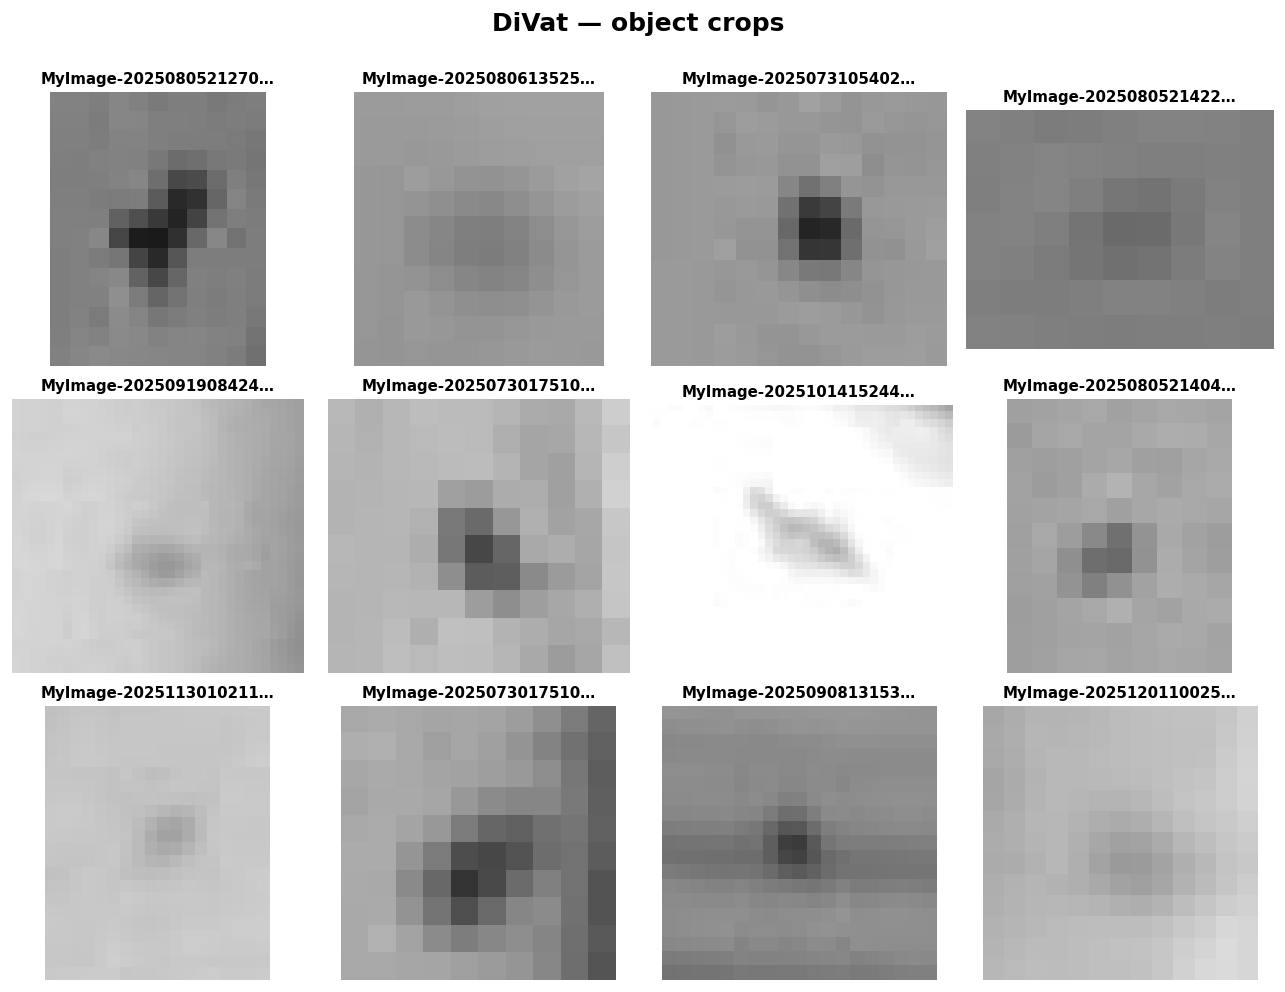

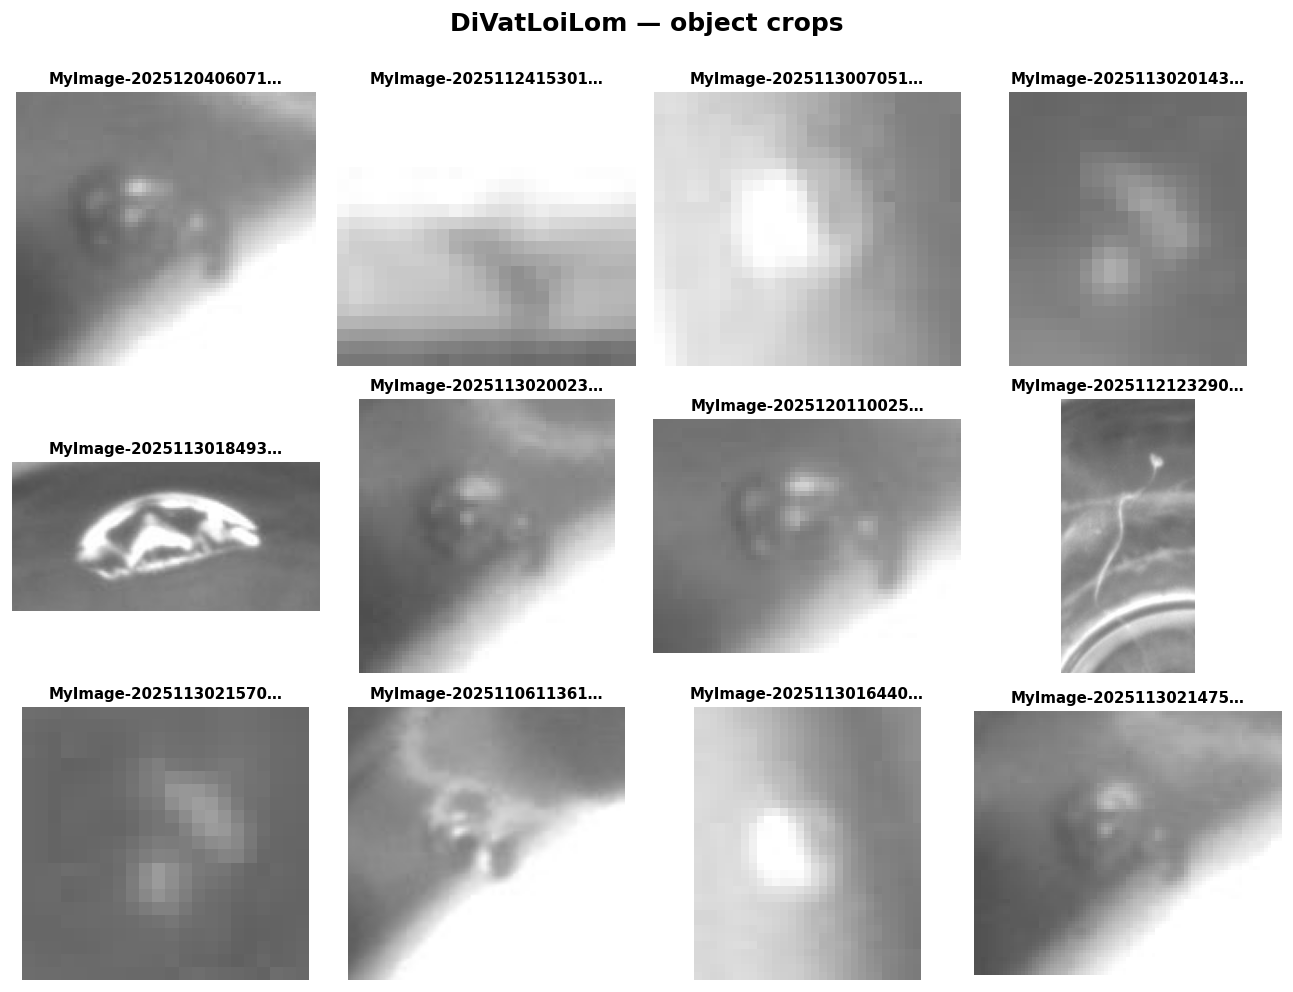

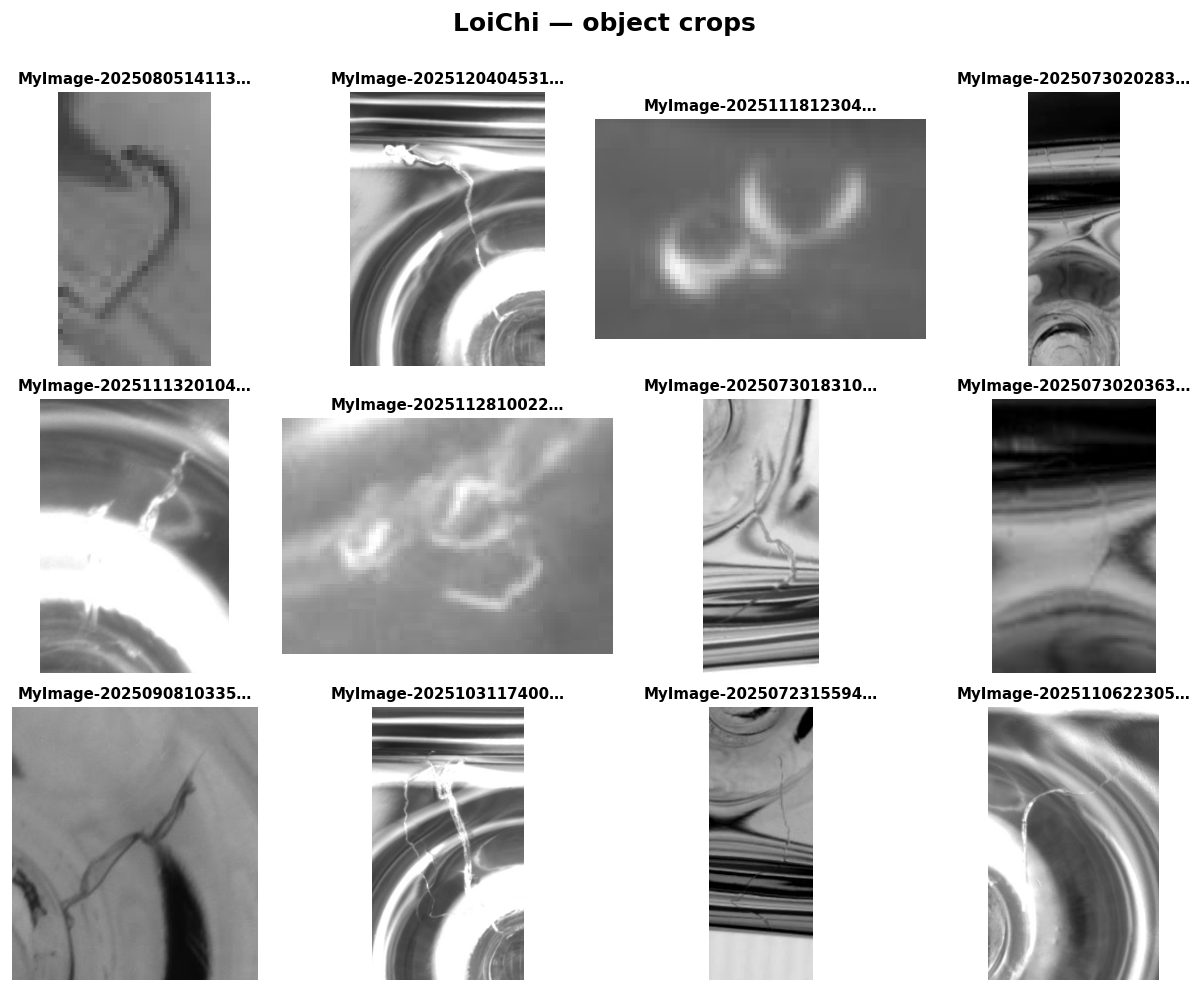

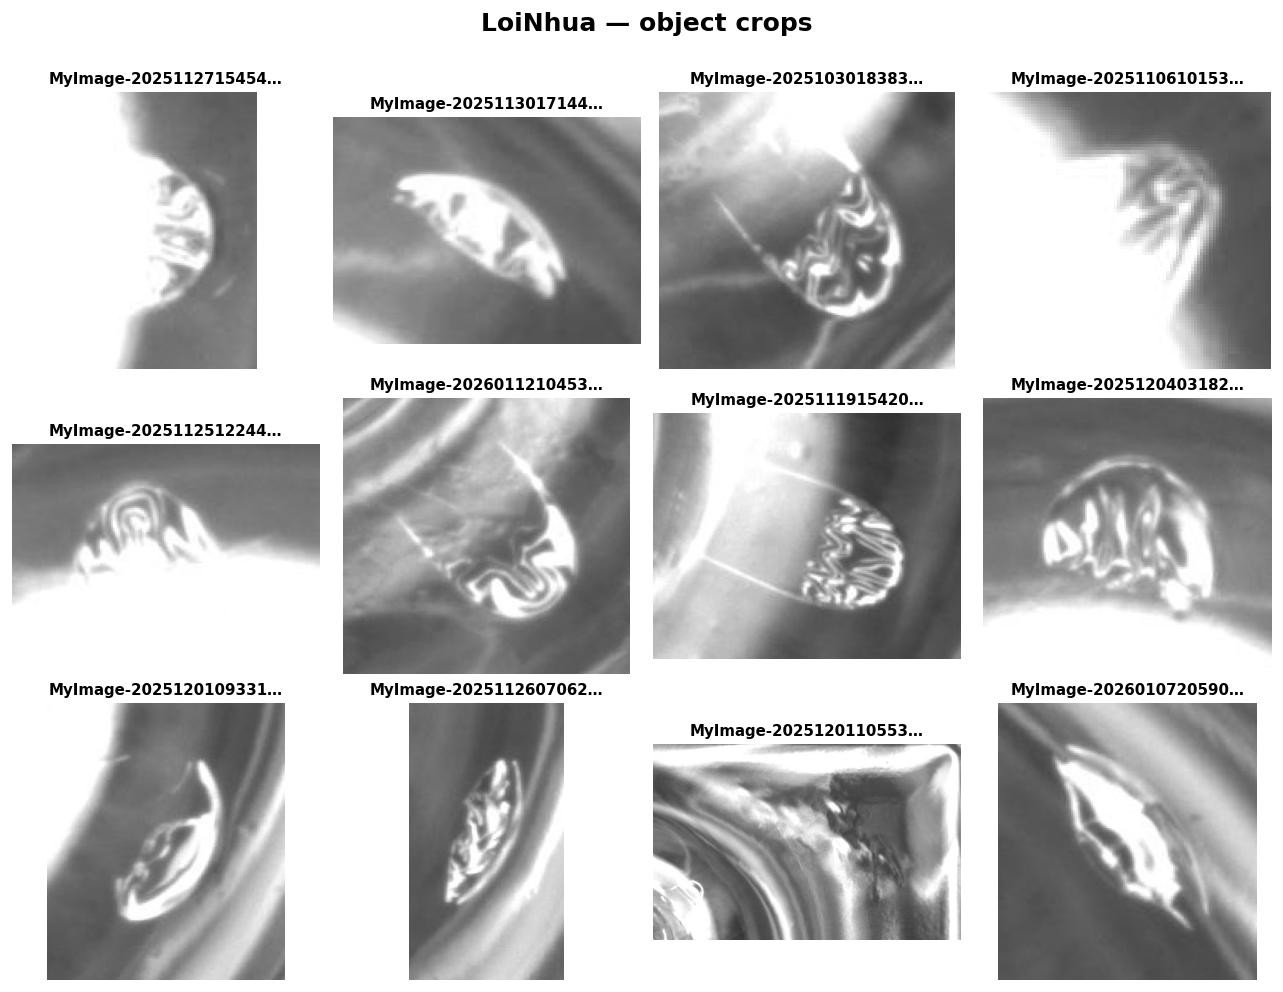

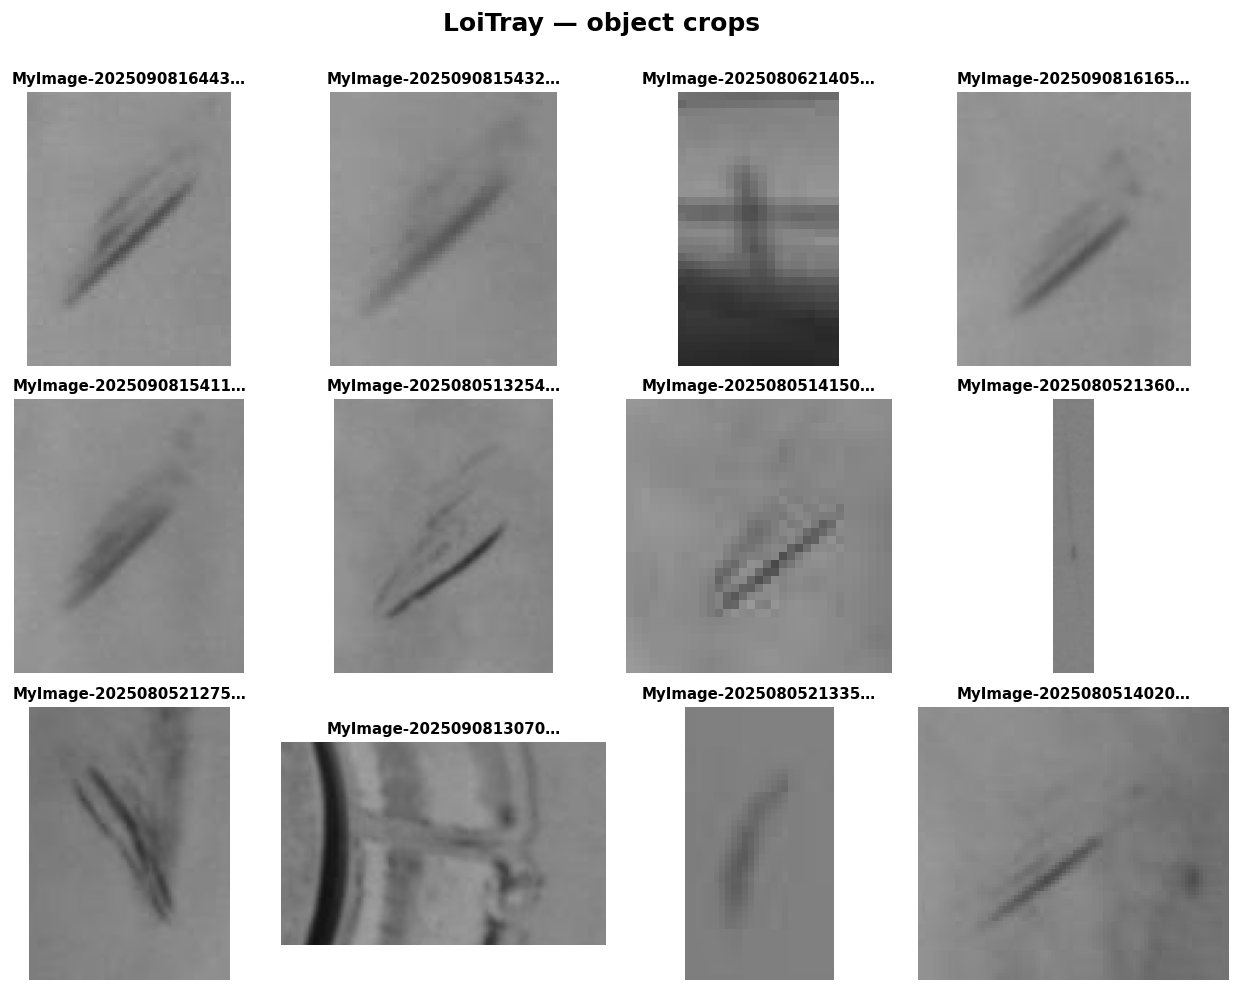

In [8]:
def class_crop_gallery(class_id: int, n: int = 12, padding_ratio: float = 0.25):
    subset = object_df[
        (object_df["split"] == "train")
        & (object_df["class_id"] == class_id)
    ]

    if subset.empty:
        return []

    chosen = subset.sample(n=min(n, len(subset)), random_state=SEED + class_id)
    items = []

    for row in chosen.itertuples(index=False):
        image = Image.open(row.image_path).convert("RGB")
        box = (row.class_id, row.x, row.y, row.w, row.h)
        items.append({
            "image": crop_box(image, box, padding_ratio=padding_ratio),
            "title": short_name(row.image_path, 22),
        })
    return items


for class_id, class_name in CLASS_NAMES.items():
    show_gallery(
        class_crop_gallery(class_id, n=12),
        title=f"{class_name} — object crops",
        cols=4,
        cell_size=2.7,
    )


## 9. Representative full images theo class

Crop cho biết defect trông như thế nào; full image cho biết defect xuất hiện trong context nào.

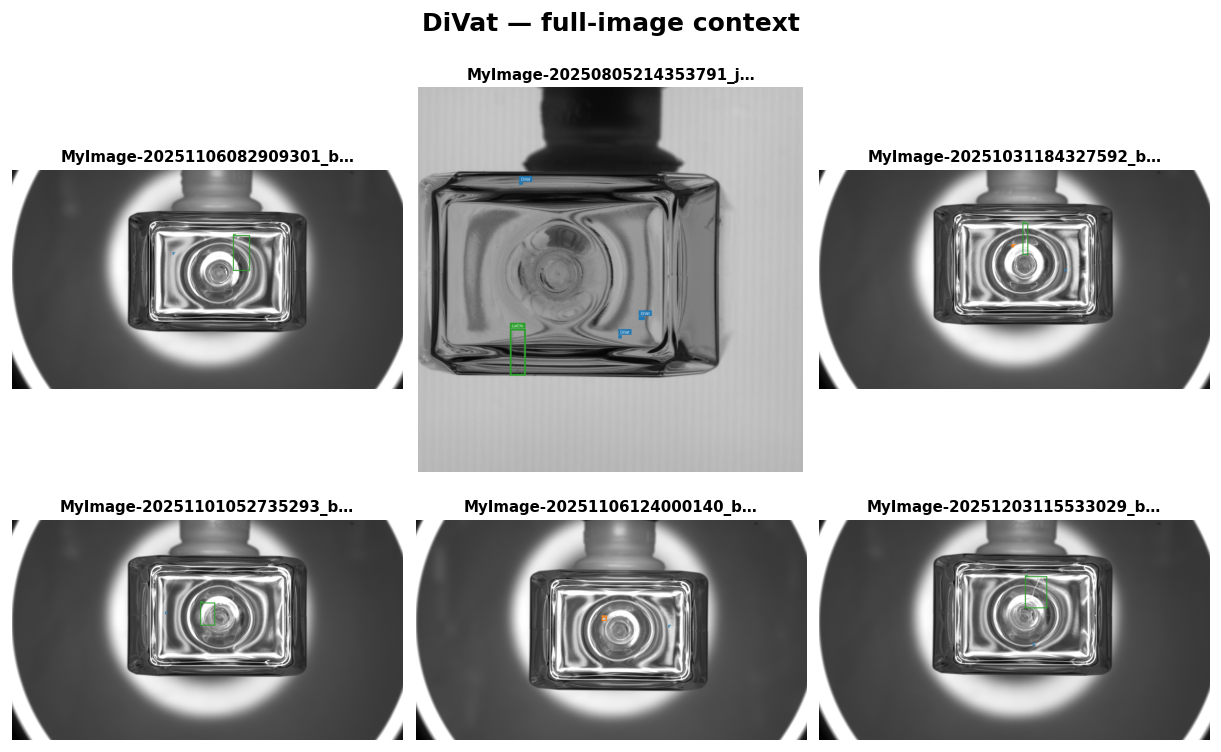

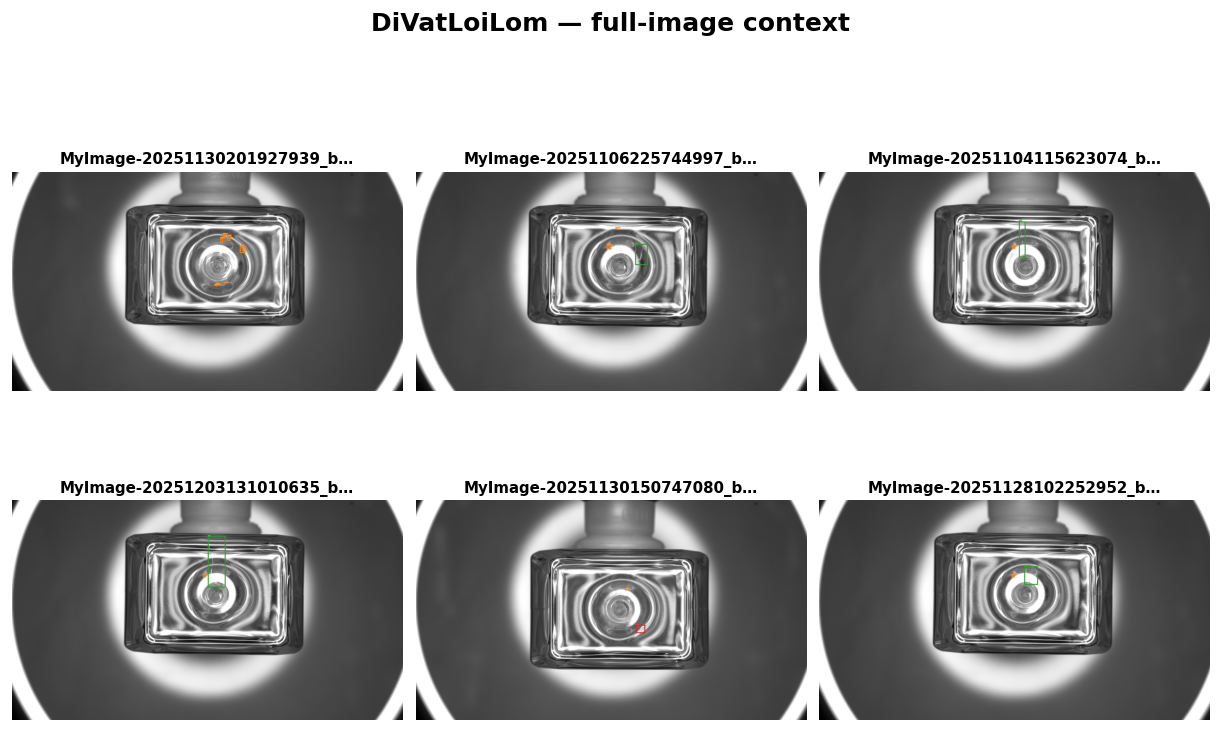

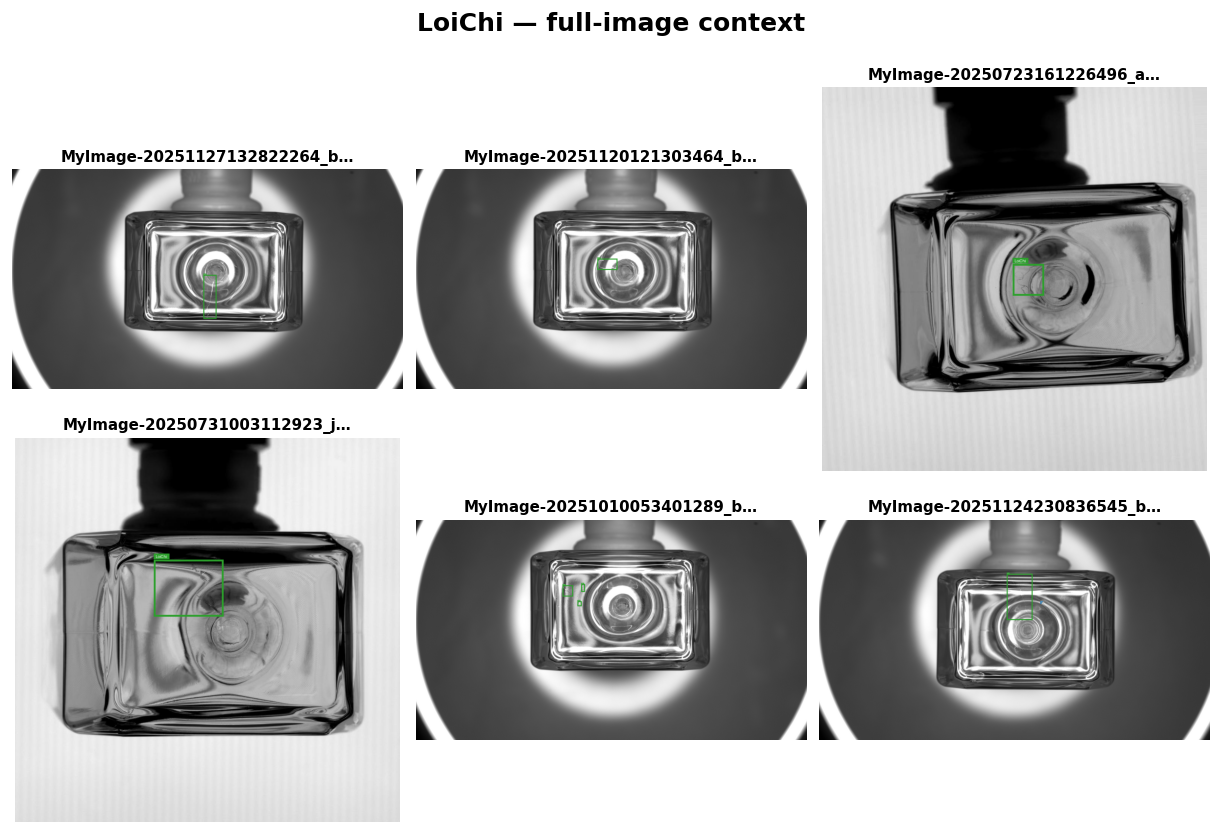

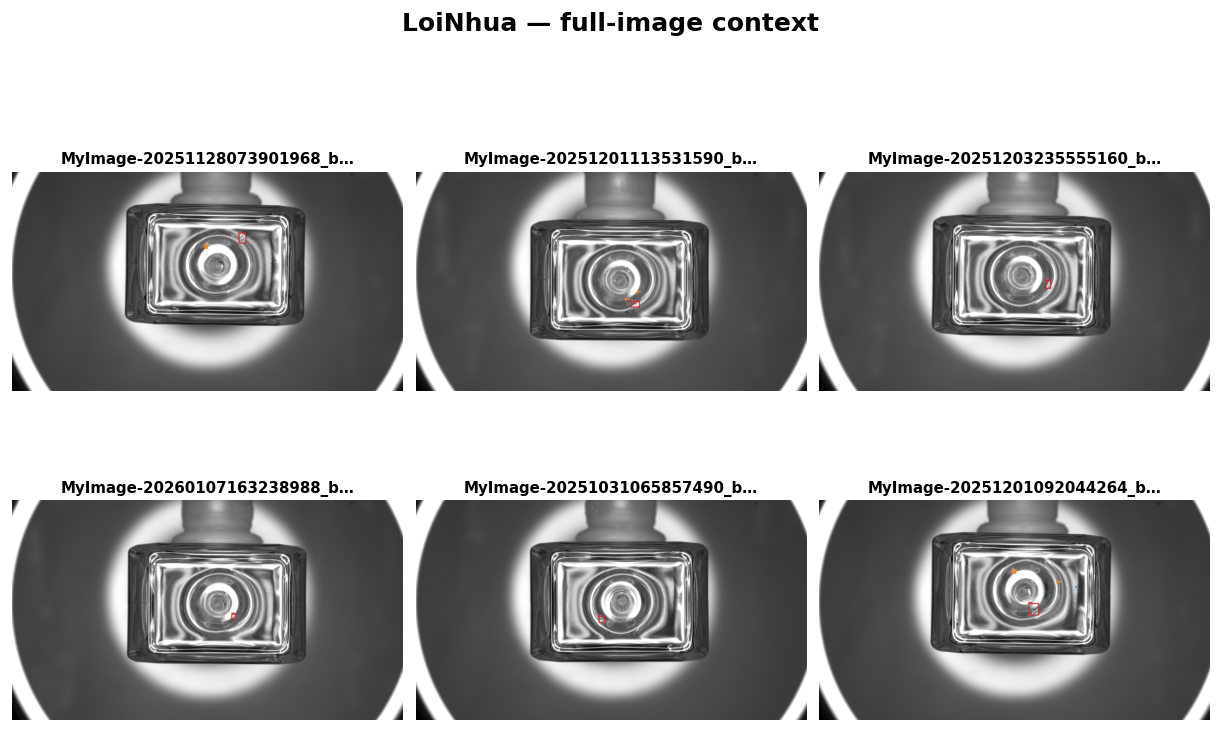

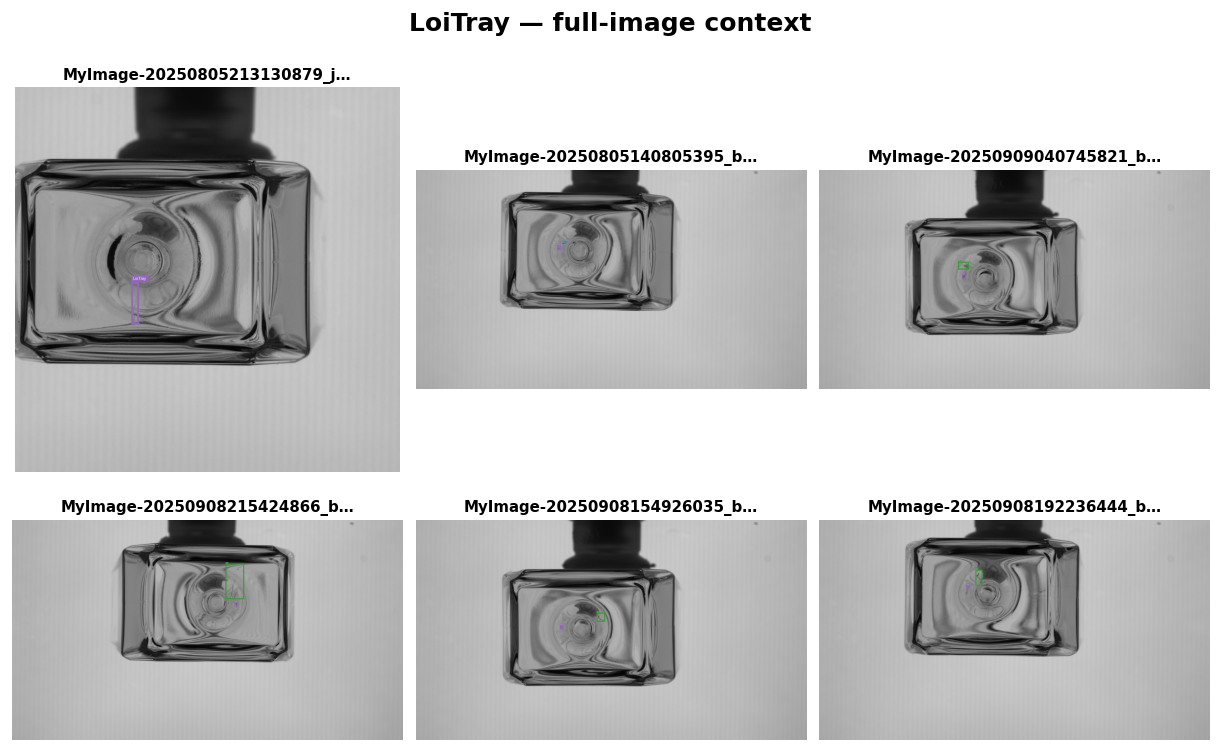

In [9]:
for class_id, class_name in CLASS_NAMES.items():
    paths = (
        object_df.loc[
            (object_df["split"] == "train") & (object_df["class_id"] == class_id),
            "image_path",
        ]
        .drop_duplicates()
        .tolist()
    )

    items = []
    for image_path in sample_paths(paths, n=6):
        label_path = label_path_for_image(image_path, train_dir)
        items.append({
            "image": draw_boxes(image_path, label_path),
            "title": short_name(image_path),
        })

    show_gallery(items, title=f"{class_name} — full-image context", cols=3, cell_size=3.4)


# PHẦN C — SCALE & HARD CASES

## 10. Bounding-box scale theo class

`area = w × h` là diện tích bbox chuẩn hóa theo toàn ảnh. Trục log giúp nhìn rõ object rất nhỏ mà không bị các box lớn ép mất.

C:\Users\PC\AppData\Local\Temp\ipykernel_27180\48105976.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


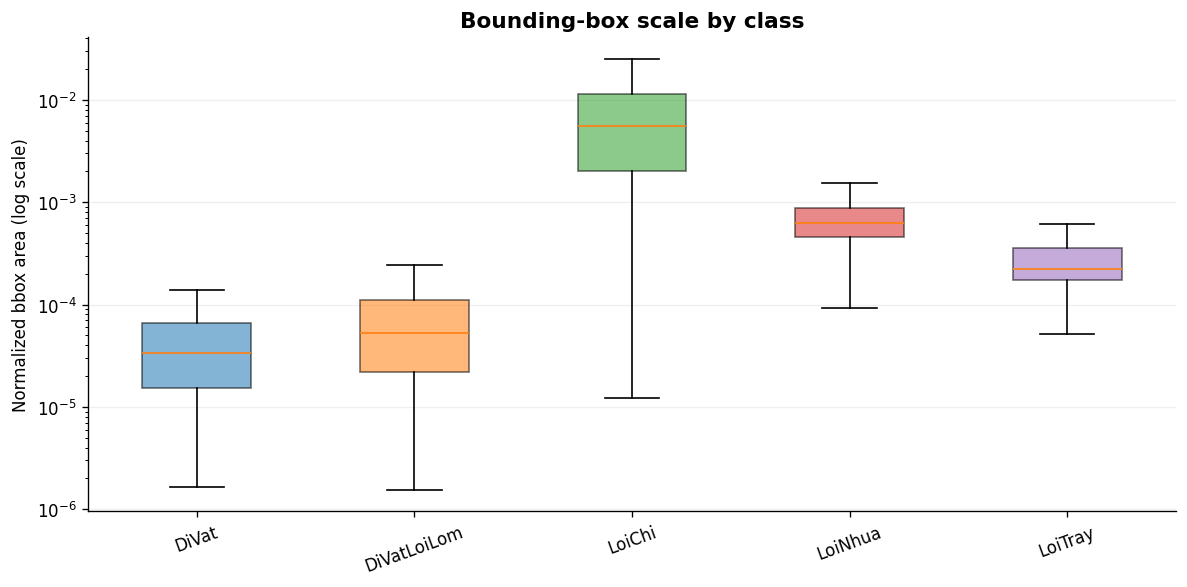

In [10]:
train_obj = object_df[object_df["split"] == "train"].copy()

fig, ax = plt.subplots(figsize=(10, 5))
series = [
    train_obj.loc[train_obj["class_id"] == class_id, "area"]
    .clip(lower=1e-8)
    .values
    for class_id in CLASS_NAMES
]

bp = ax.boxplot(
    series,
    labels=list(CLASS_NAMES.values()),
    showfliers=False,
    patch_artist=True,
)
for patch, class_id in zip(bp["boxes"], CLASS_NAMES):
    rgb = np.array(CLASS_COLORS[class_id]) / 255
    patch.set_facecolor(rgb)
    patch.set_alpha(0.55)

ax.set_yscale("log")
ax.set_ylabel("Normalized bbox area (log scale)")
ax.set_title("Bounding-box scale by class")
ax.grid(axis="y", alpha=0.2)
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()


## 11. Smallest annotated defects

Xem trực tiếp các object có bbox nhỏ nhất thay vì chỉ nhìn histogram.

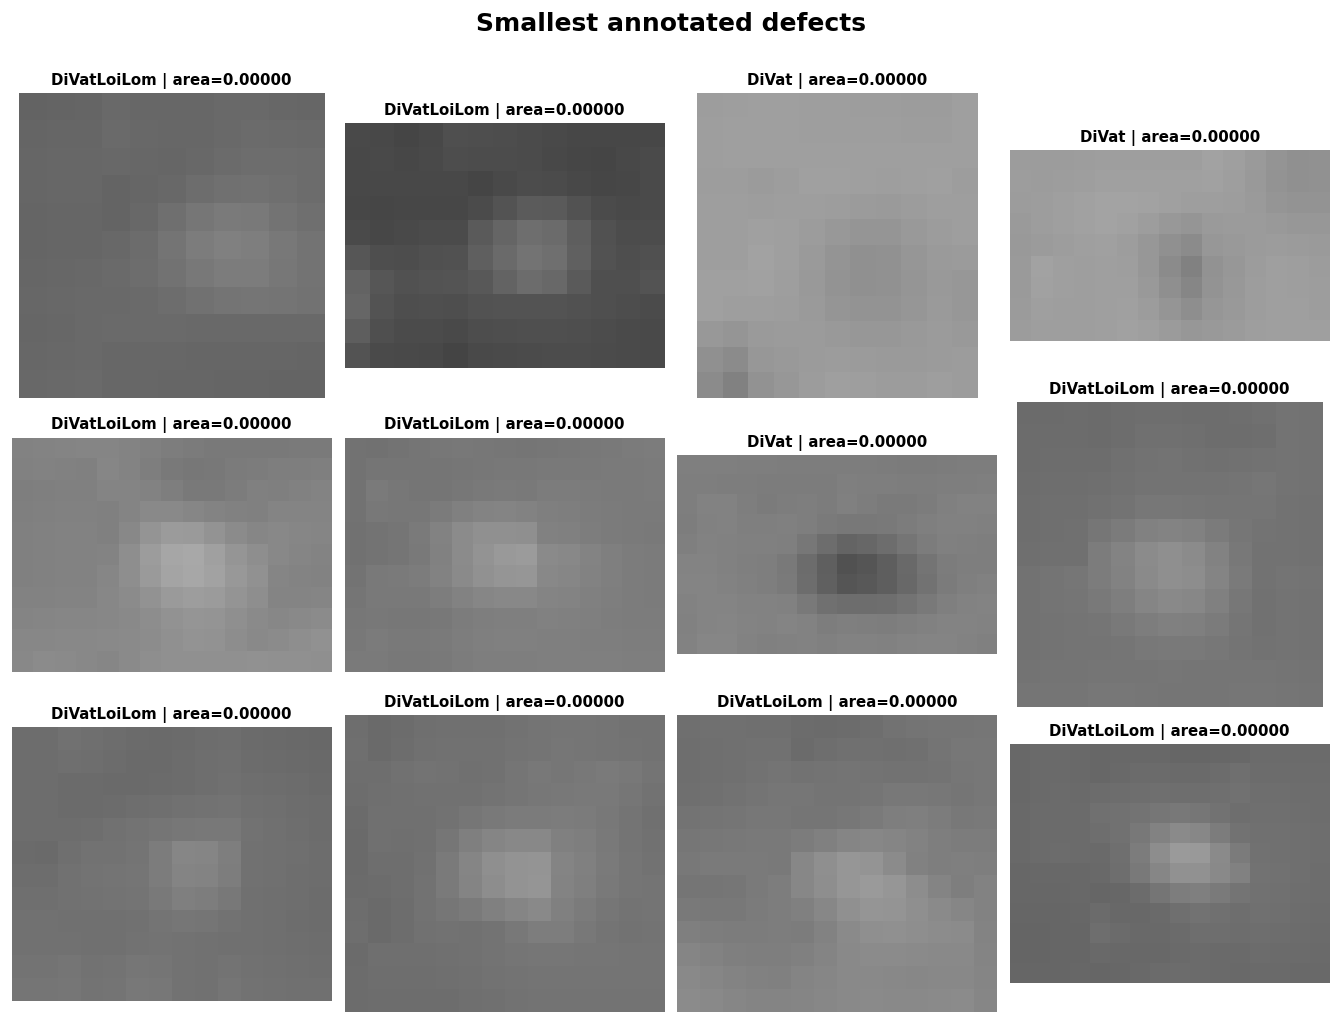

In [11]:
smallest = train_obj.nsmallest(12, "area")
items = []

for row in smallest.itertuples(index=False):
    image = Image.open(row.image_path).convert("RGB")
    box = (row.class_id, row.x, row.y, row.w, row.h)
    items.append({
        "image": crop_box(image, box, padding_ratio=0.60),
        "title": f"{row.class_name} | area={row.area:.5f}",
    })

show_gallery(items, "Smallest annotated defects", cols=4, cell_size=2.8)


## 12. Extreme aspect-ratio defects

Hai phía cực đoan được đặt trong cùng section: rất ngang và rất dọc.

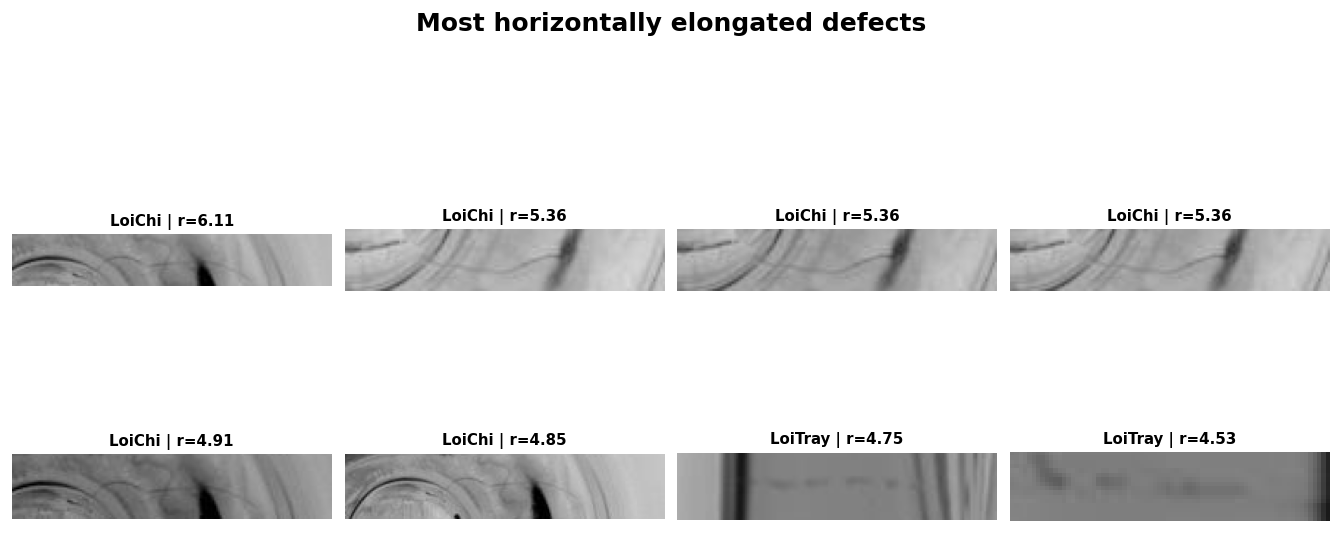

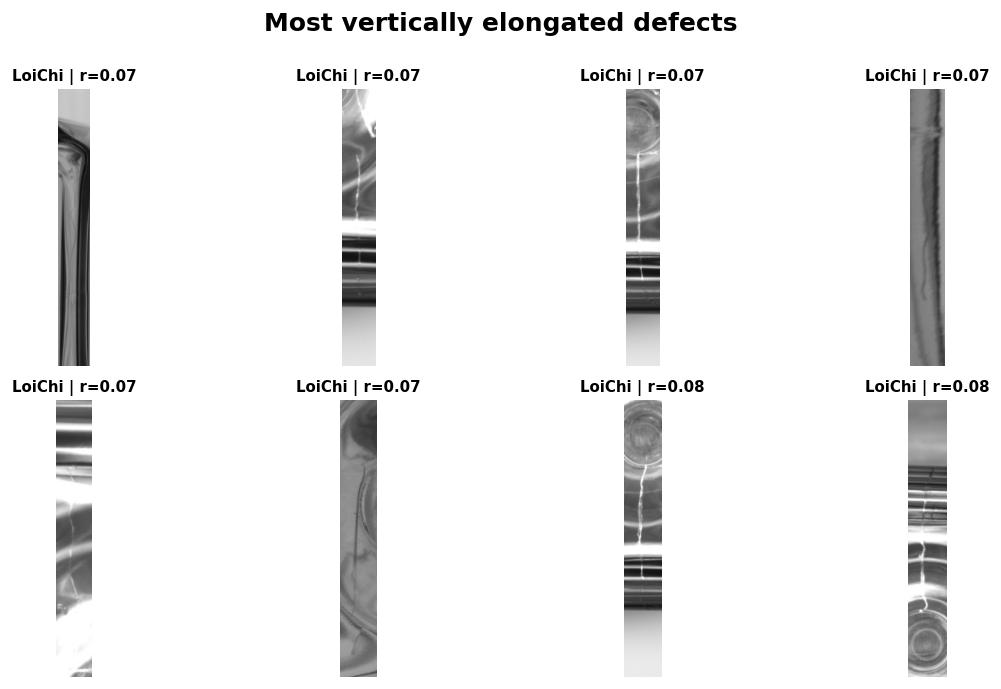

In [12]:
def object_rows_to_crops(df: pd.DataFrame, padding_ratio: float = 0.40):
    items = []
    for row in df.itertuples(index=False):
        image = Image.open(row.image_path).convert("RGB")
        box = (row.class_id, row.x, row.y, row.w, row.h)
        items.append({
            "image": crop_box(image, box, padding_ratio=padding_ratio),
            "title": f"{row.class_name} | r={row.aspect:.2f}",
        })
    return items


show_gallery(
    object_rows_to_crops(train_obj.nlargest(8, "aspect")),
    "Most horizontally elongated defects",
    cols=4,
    cell_size=2.8,
)

show_gallery(
    object_rows_to_crops(train_obj.nsmallest(8, "aspect")),
    "Most vertically elongated defects",
    cols=4,
    cell_size=2.8,
)


## 13. Images with most defects

Các scene đông object dễ gặp miss detection, box gần nhau hoặc NMS khó.

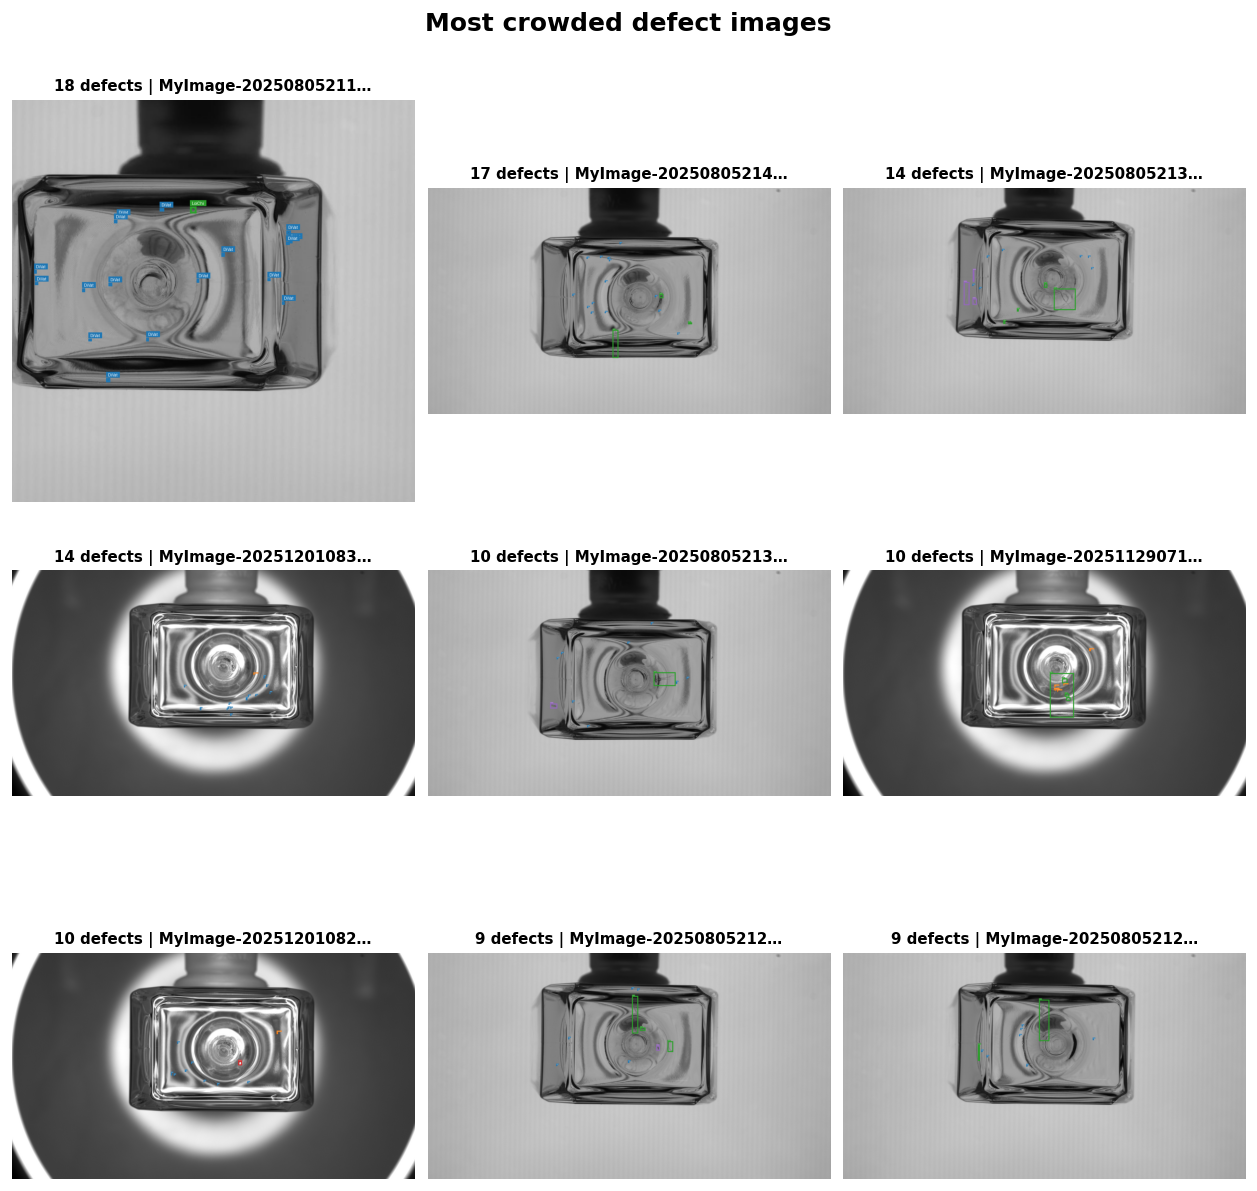

In [13]:
crowded = image_df[image_df["split"] == "train"].nlargest(9, "n_objects")

items = []
for row in crowded.itertuples(index=False):
    items.append({
        "image": draw_boxes(row.image_path, row.label_path),
        "title": f"{row.n_objects} defects | {short_name(row.image_path, 20)}",
    })

show_gallery(items, "Most crowded defect images", cols=3, cell_size=3.5)


# PHẦN D — ANNOTATION SANITY CHECK

## 14. Missing / empty / malformed labels

Đây là audit logic trước khi train: tách rõ **missing label file**, **label rỗng**, và **line lỗi cú pháp/class**.

In [14]:
train_images_df = image_df[image_df["split"] == "train"].copy()

sanity = pd.DataFrame({
    "check": [
        "Images",
        "Missing label file",
        "Empty annotation",
        "Malformed / invalid label lines",
    ],
    "count": [
        len(train_images_df),
        int((~train_images_df["label_exists"]).sum()),
        int((train_images_df["n_objects"] == 0).sum()),
        int((issue_df["split"] == "train").sum()) if not issue_df.empty else 0,
    ],
})

display(sanity)

if not issue_df.empty:
    display(issue_df[issue_df["split"] == "train"].head(20))


,check,count
0,Images,5578
1,Missing label file,0
2,Empty annotation,0
3,Malformed / invalid label lines,0


## 15. Negative samples / ảnh không có bbox

In [15]:
empty_df = train_images_df[train_images_df["n_objects"] == 0]
print(f"Train images without bbox: {len(empty_df)}")

items = []
for image_path in sample_paths(empty_df["image_path"].tolist(), n=9):
    items.append({
        "image": Image.open(image_path).convert("RGB"),
        "title": short_name(image_path),
    })

show_gallery(items, "Images without annotated defects", cols=3, cell_size=3.4)


Train images without bbox: 0
Không có ảnh phù hợp.


## 16. Boxes closest to / outside image borders

`edge_distance < 0` nghĩa là bbox vượt khỏi biên chuẩn hóa của ảnh và cần kiểm tra annotation.

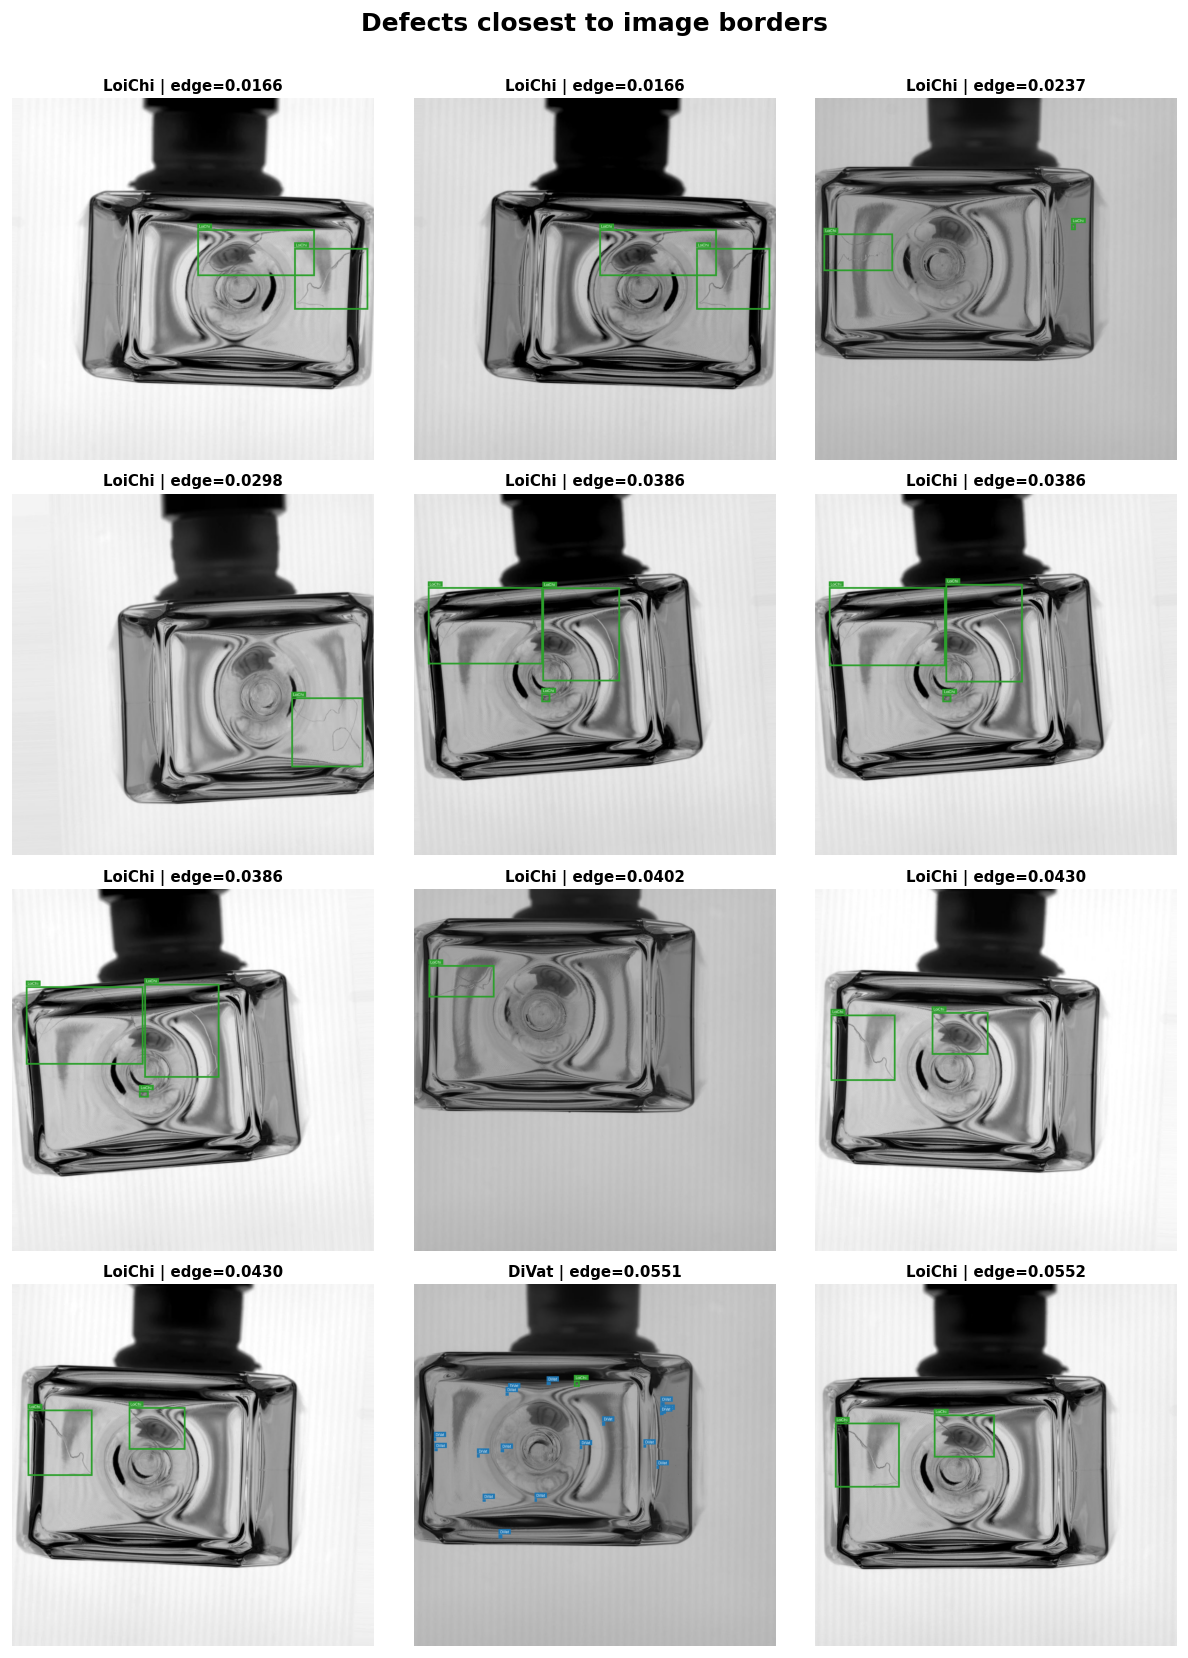

In [16]:
border_cases = train_obj.sort_values("edge_distance").head(12)

items = []
seen = set()
for row in border_cases.itertuples(index=False):
    if row.image_path in seen:
        continue
    seen.add(row.image_path)
    status = "OUTSIDE" if row.edge_distance < 0 else f"edge={row.edge_distance:.4f}"
    items.append({
        "image": draw_boxes(row.image_path, row.label_path),
        "title": f"{row.class_name} | {status}",
    })

show_gallery(items, "Defects closest to image borders", cols=3, cell_size=3.4)


# PHẦN E — FINAL VISUAL MONTAGE

## 17. Final annotated montage

Một grid cuối để scan nhanh độ đồng nhất của annotation trước khi chuyển sang train.

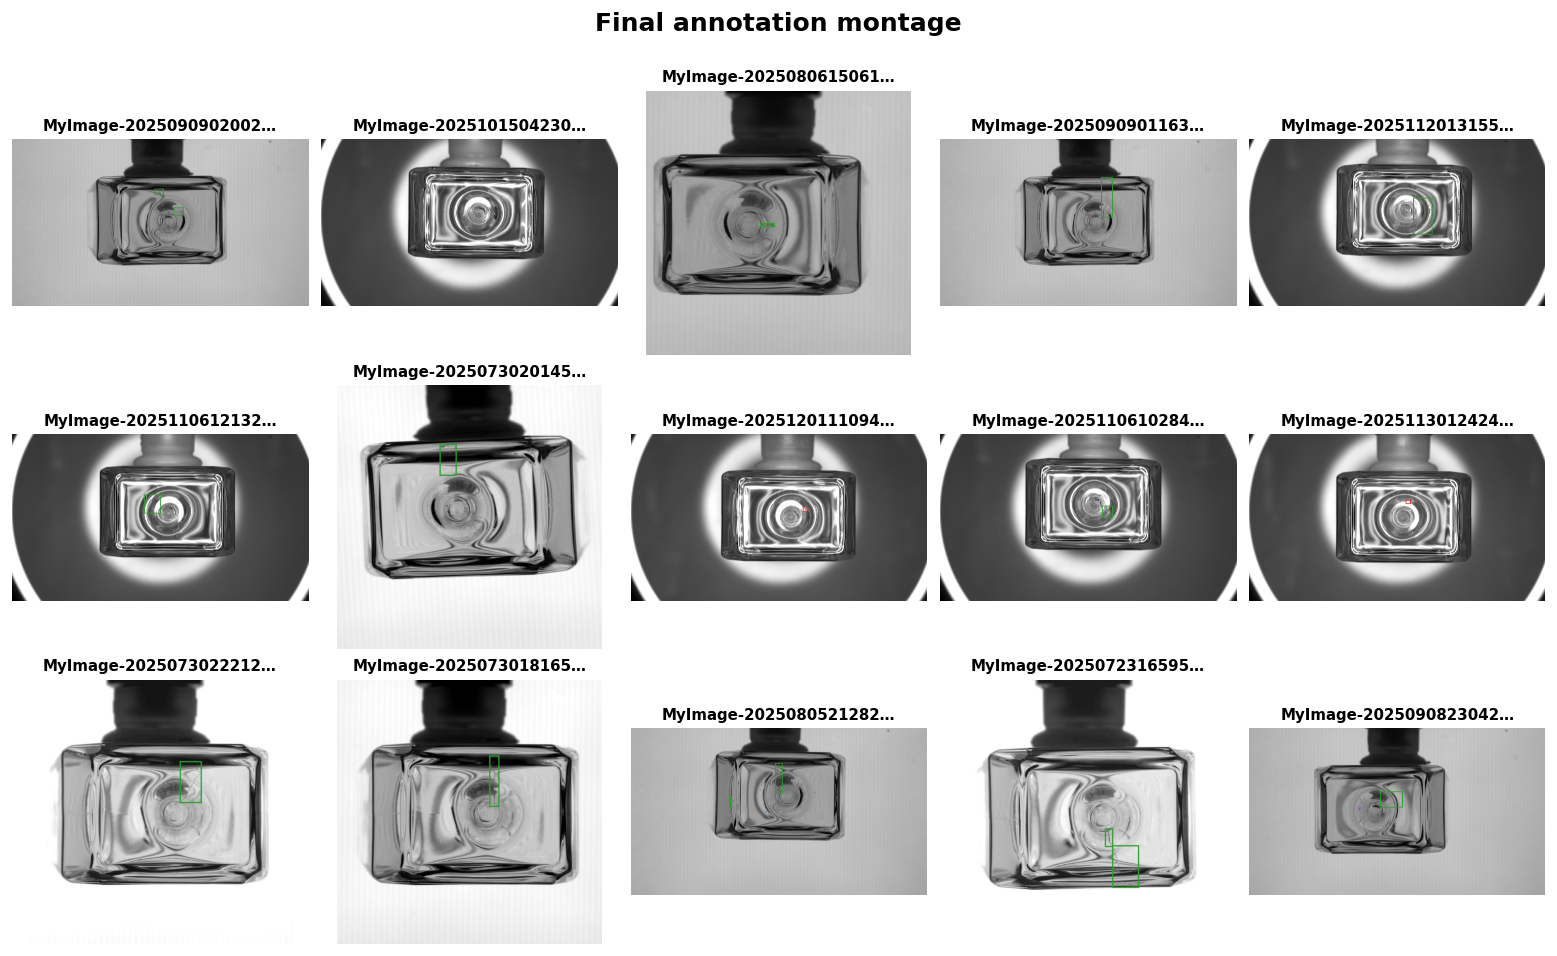

In [17]:
items = []
for image_path in sample_paths(train_images, n=15):
    label_path = label_path_for_image(image_path, train_dir)
    items.append({
        "image": draw_boxes(image_path, label_path, show_labels=False),
        "title": short_name(image_path, 22),
    })

show_gallery(items, "Final annotation montage", cols=5, cell_size=2.6)
